In [2]:
import csv
import random
from datetime import date, timedelta
from pathlib import Path


OUTPUT_PATH = Path.home() / "Downloads" / "raw_orders.csv"
ROW_COUNT = 2_500


def build_rows():
    randomizer = random.Random(42)
    products = ["Notebook", "Pen Set", "Desk Lamp", "Water Bottle", "Backpack"]
    countries = ["United States", "Canada", "United Kingdom", "Australia"]
    start_date = date(2024, 1, 1)
    rows = []

    for index in range(ROW_COUNT):
        if index and index % 97 == 0:
            duplicate = rows[-1].copy()
            duplicate["order_id"] = rows[-2]["order_id"]
            rows.append(duplicate)
            continue

        order_date = start_date + timedelta(days=randomizer.randrange(365))
        date_formats = [
            order_date.isoformat(),
            order_date.strftime("%m/%d/%Y"),
            order_date.strftime("%d-%b-%Y"),
        ]
        row = {
            "order_id": f"ORD-{index + 1:05d}",
            "customer_id": f"CUST-{randomizer.randint(1, 800):04d}",
            "order_date": randomizer.choice(date_formats),
            "product": randomizer.choice(products),
            "quantity": str(randomizer.randint(1, 8)),
            "unit_price": f"{randomizer.uniform(3, 180):.2f}",
            "country": randomizer.choice(countries),
        }

        if index % 11 == 0:
            row["product"] = f"  {row['product'].lower()}  "
        if index % 13 == 0:
            row["country"] = f" {row['country'].upper()} "
        if index % 101 == 0:
            row["order_date"] = "not-a-date"
        if index % 127 == 0:
            row["quantity"] = "unknown"
        if index % 149 == 0:
            row["unit_price"] = ""
        if index % 173 == 0:
            row["customer_id"] = " "
        if index % 191 == 0:
            row["product"] = ""

        rows.append(row)

    return rows


def main():
    OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    with OUTPUT_PATH.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.DictWriter(
            output_file,
            fieldnames=[
                "order_id",
                "customer_id",
                "order_date",
                "product",
                "quantity",
                "unit_price",
                "country",
            ],
        )
        writer.writeheader()
        writer.writerows(build_rows())
    print(f"Generated {ROW_COUNT} rows at {OUTPUT_PATH}")


if __name__ == "__main__":
    main()

Generated 2500 rows at /home/sj/Downloads/raw_orders.csv


In [7]:
import argparse
import csv
import json
import os
import tempfile
from datetime import datetime
from decimal import Decimal, InvalidOperation, ROUND_HALF_UP
from pathlib import Path


# ============================================================
# CONFIGURATION
# ============================================================

REQUIRED_COLUMNS = (
    "order_id",
    "customer_id",
    "order_date",
    "product",
    "quantity",
    "unit_price",
    "country",
)

OUTPUT_COLUMNS = (*REQUIRED_COLUMNS, "total")

COUNTRY_NAMES = {
    "australia": "Australia",
    "canada": "Canada",
    "united kingdom": "United Kingdom",
    "united states": "United States",
}

DATE_FORMATS = ("%Y-%m-%d", "%m/%d/%Y", "%d-%b-%Y")

CENT = Decimal("0.01")


# ============================================================
# PATH UTILITIES
# ============================================================

def normalize_header(header):
    """Normalize a CSV column name."""
    if header is None:
        return ""

    return header.strip().lstrip("\ufeff").strip().lower()


def normalized_identifier(value):
    """Normalize an identifier for comparisons."""
    return (value or "").strip().upper()


def ensure_distinct_paths(input_path, output_path, report_path):
    """Prevent input/output/report path collisions."""
    input_path = input_path.resolve()
    output_path = output_path.resolve()
    report_path = report_path.resolve()

    if input_path == output_path:
        raise ValueError("Input and output paths must be different.")

    if input_path == report_path:
        raise ValueError("Input and report paths must be different.")

    if output_path == report_path:
        raise ValueError("Output and report paths must be different.")


# ============================================================
# VALIDATION AND CLEANING
# ============================================================

def parse_order_date(value):
    """Parse supported date formats and return ISO 8601 dates."""
    value = (value or "").strip()

    for date_format in DATE_FORMATS:
        try:
            parsed_date = datetime.strptime(value, date_format).date()
            return parsed_date.isoformat()
        except ValueError:
            continue

    raise ValueError(
        "order_date must use YYYY-MM-DD, MM/DD/YYYY, "
        "or DD-Mon-YYYY format"
    )


def parse_quantity(value):
    """Validate quantity as a positive integer."""
    value = (value or "").strip()

    try:
        quantity = int(value)
    except (ValueError, TypeError) as error:
        raise ValueError(
            "quantity must be a positive integer"
        ) from error

    if quantity <= 0:
        raise ValueError("quantity must be a positive integer")

    return quantity


def parse_unit_price(value):
    """Parse a finite, non-negative monetary value."""
    value = (value or "").strip()

    try:
        price = Decimal(value)
    except (InvalidOperation, ValueError, TypeError) as error:
        raise ValueError(
            "unit_price must be a non-negative number"
        ) from error

    if not price.is_finite() or price < 0:
        raise ValueError(
            "unit_price must be a finite, non-negative number"
        )

    return price.quantize(CENT, rounding=ROUND_HALF_UP)


def clean_row(row):
    """Validate and normalize one CSV record."""
    values = {
        key: (value.strip() if isinstance(value, str) else "")
        for key, value in row.items()
        if isinstance(key, str)
    }

    missing = [
        column
        for column in REQUIRED_COLUMNS
        if not values.get(column)
    ]

    if missing:
        raise ValueError(
            f"missing required value: {', '.join(missing)}"
        )

    quantity = parse_quantity(values["quantity"])
    unit_price = parse_unit_price(values["unit_price"])

    country_key = values["country"].casefold()
    country = COUNTRY_NAMES.get(country_key)

    if country is None:
        raise ValueError(
            f"unrecognized country: {values['country']!r}"
        )

    order_id = normalized_identifier(values["order_id"])
    customer_id = normalized_identifier(values["customer_id"])

    if not order_id:
        raise ValueError("order_id cannot be empty")

    if not customer_id:
        raise ValueError("customer_id cannot be empty")

    total = (Decimal(quantity) * unit_price).quantize(
        CENT,
        rounding=ROUND_HALF_UP,
    )

    return {
        "order_id": order_id,
        "customer_id": customer_id,
        "order_date": parse_order_date(values["order_date"]),
        "product": values["product"].title(),
        "quantity": quantity,
        "unit_price": f"{unit_price:.2f}",
        "country": country,
        "total": f"{total:.2f}",
    }


# ============================================================
# ATOMIC FILE WRITING
# ============================================================

def atomic_write_csv(output_path, rows):
    """Write the CSV to a temporary file before replacing the target."""
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    temporary_path = None

    try:
        with tempfile.NamedTemporaryFile(
            mode="w",
            newline="",
            encoding="utf-8",
            dir=output_path.parent,
            prefix=f".{output_path.name}.",
            suffix=".tmp",
            delete=False,
        ) as output_file:
            temporary_path = Path(output_file.name)

            writer = csv.DictWriter(
                output_file,
                fieldnames=OUTPUT_COLUMNS,
                extrasaction="raise",
            )
            writer.writeheader()
            writer.writerows(rows)

        os.replace(temporary_path, output_path)

    finally:
        if temporary_path is not None and temporary_path.exists():
            temporary_path.unlink()


def atomic_write_json(report_path, report):
    """Write a JSON report to a temporary file before replacing the target."""
    report_path = Path(report_path)
    report_path.parent.mkdir(parents=True, exist_ok=True)

    temporary_path = None

    try:
        with tempfile.NamedTemporaryFile(
            mode="w",
            encoding="utf-8",
            dir=report_path.parent,
            prefix=f".{report_path.name}.",
            suffix=".tmp",
            delete=False,
        ) as report_file:
            temporary_path = Path(report_file.name)

            json.dump(report, report_file, indent=2, ensure_ascii=False)
            report_file.write("\n")

        os.replace(temporary_path, report_path)

    finally:
        if temporary_path is not None and temporary_path.exists():
            temporary_path.unlink()


# ============================================================
# MAIN DATA PIPELINE
# ============================================================

def run_pipeline(input_path, output_path, report_path):
    input_path = Path(input_path).expanduser()
    output_path = Path(output_path).expanduser()
    report_path = Path(report_path).expanduser()

    ensure_distinct_paths(input_path, output_path, report_path)

    if not input_path.is_file():
        raise FileNotFoundError(
            f"Input CSV does not exist: {input_path}"
        )

    cleaned_rows = []
    rejected_records = []
    seen_order_ids = set()

    rows_read = 0
    rejected_rows = 0
    duplicate_rows = 0

    # --------------------------------------------------------
    # READ AND VALIDATE INPUT
    # --------------------------------------------------------

    with input_path.open(
        mode="r",
        newline="",
        encoding="utf-8-sig",
    ) as input_file:

        reader = csv.DictReader(input_file)

        if not reader.fieldnames:
            raise ValueError("Input CSV is empty or has no header.")

        original_headers = reader.fieldnames
        normalized_headers = [
            normalize_header(header)
            for header in original_headers
        ]

        if len(normalized_headers) != len(set(normalized_headers)):
            raise ValueError(
                "Input CSV contains duplicate column names "
                "after header normalization."
            )

        reader.fieldnames = normalized_headers

        missing_columns = (
            set(REQUIRED_COLUMNS) - set(normalized_headers)
        )

        if missing_columns:
            raise ValueError(
                "Input is missing required columns: "
                + ", ".join(sorted(missing_columns))
            )

        try:
            for row_number, row in enumerate(reader, start=2):
                rows_read += 1

                # Detect malformed CSV records with extra fields.
                if None in row:
                    rejected_rows += 1
                    rejected_records.append({
                        "row_number": row_number,
                        "order_id": "",
                        "reason": "row contains more fields than the header",
                    })
                    continue

                # Detect missing trailing fields.
                if any(value is None for value in row.values()):
                    rejected_rows += 1
                    rejected_records.append({
                        "row_number": row_number,
                        "order_id": normalized_identifier(
                            row.get("order_id")
                        ),
                        "reason": "row contains missing fields",
                    })
                    continue

                try:
                    cleaned_row = clean_row(row)
                except ValueError as error:
                    rejected_rows += 1
                    rejected_records.append({
                        "row_number": row_number,
                        "order_id": normalized_identifier(
                            row.get("order_id")
                        ),
                        "reason": str(error),
                    })
                    continue

                order_id = cleaned_row["order_id"]

                # Keep the first valid occurrence of each order ID.
                if order_id in seen_order_ids:
                    duplicate_rows += 1
                    continue

                seen_order_ids.add(order_id)
                cleaned_rows.append(cleaned_row)

        except csv.Error as error:
            raise ValueError(
                f"Malformed CSV data near line {reader.line_num}: {error}"
            ) from error

    # --------------------------------------------------------
    # WRITE CLEANED DATA AND QUALITY REPORT
    # --------------------------------------------------------

    atomic_write_csv(output_path, cleaned_rows)

    report = {
        "status": "completed",
        "input_file": str(input_path.resolve()),
        "output_file": str(output_path.resolve()),
        "rows_read": rows_read,
        "rows_written": len(cleaned_rows),
        "rows_rejected": rejected_rows,
        "duplicate_rows_removed": duplicate_rows,
        "rejected_records": rejected_records,
    }

    atomic_write_json(report_path, report)

    return report


# ============================================================
# COMMAND-LINE INTERFACE
# ============================================================

def main(argv=None):
    downloads = Path.home() / "Downloads"

    parser = argparse.ArgumentParser(
        description="Validate, clean, and report on an orders CSV."
    )

    parser.add_argument(
        "--input",
        default=str(downloads / "raw_orders.csv"),
    )
    parser.add_argument(
        "--output",
        default=str(downloads / "cleaned_orders.csv"),
    )
    parser.add_argument(
        "--report",
        default=str(downloads / "quality_report.json"),
    )

    # Explicit argv lets Jupyter run without parsing its own arguments.
    arguments = parser.parse_args(argv)

    try:
        report = run_pipeline(
            input_path=arguments.input,
            output_path=arguments.output,
            report_path=arguments.report,
        )
        print(json.dumps(report, indent=2, ensure_ascii=False))

    except (OSError, ValueError) as error:
        parser.exit(status=1, message=f"ERROR: {error}\n")

if __name__ == "__main__":
    main([])

{
  "status": "completed",
  "input_file": "/home/sj/Downloads/raw_orders.csv",
  "output_file": "/home/sj/Downloads/cleaned_orders.csv",
  "rows_read": 2500,
  "rows_written": 2388,
  "rows_rejected": 88,
  "duplicate_rows_removed": 24,
  "rejected_records": [
    {
      "row_number": 2,
      "order_id": "ORD-00001",
      "reason": "missing required value: customer_id, product, unit_price"
    },
    {
      "row_number": 103,
      "order_id": "ORD-00102",
      "reason": "order_date must use YYYY-MM-DD, MM/DD/YYYY, or DD-Mon-YYYY format"
    },
    {
      "row_number": 129,
      "order_id": "ORD-00128",
      "reason": "quantity must be a positive integer"
    },
    {
      "row_number": 151,
      "order_id": "ORD-00150",
      "reason": "missing required value: unit_price"
    },
    {
      "row_number": 175,
      "order_id": "ORD-00174",
      "reason": "missing required value: customer_id"
    },
    {
      "row_number": 193,
      "order_id": "ORD-00192",
      "reason

In [6]:
from pathlib import Path

downloads = Path.home() / "Downloads"
input_file = downloads / "raw_orders.csv"

print("Downloads directory:", downloads)
print("Input file exists:", input_file.exists())
print("Input path:", input_file)

Downloads directory: /home/sj/Downloads
Input file exists: True
Input path: /home/sj/Downloads/raw_orders.csv


Loaded 2,388 rows from /home/sj/Downloads/cleaned_orders.csv
Showing dashboard in the IDE plotting pane/window. Close the figure to finish.


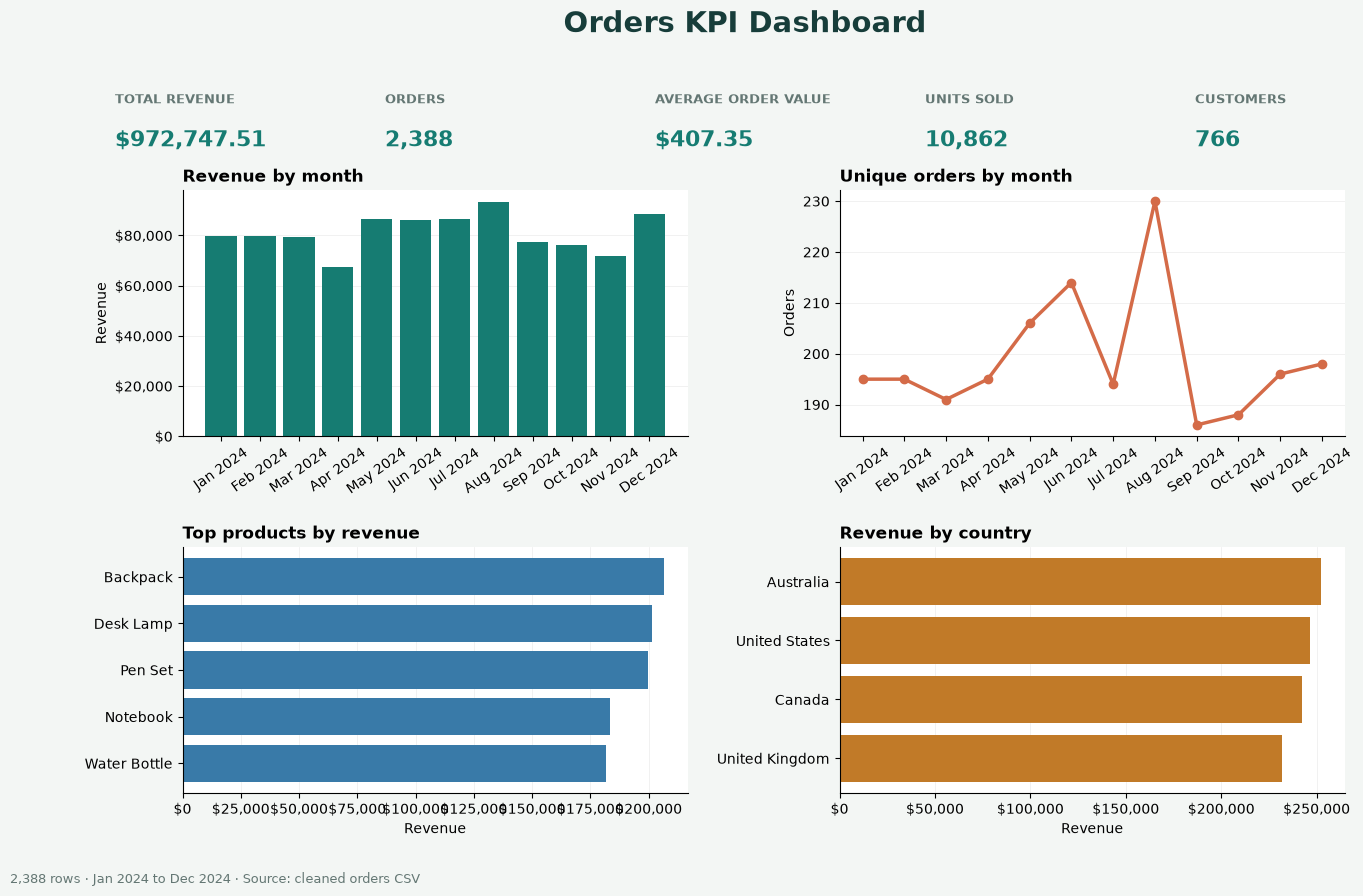

In [14]:
"""Display an orders KPI dashboard using Matplotlib, locally in PyCharm/Jupyter.

Input CSV expected columns:
order_id, customer_id, order_date, product, quantity, country, total

Run from a terminal:
    python3 orders_kpi_dashboard.py

Run from a Jupyter notebook:
    from orders_kpi_dashboard import main
    main([])
"""

import argparse
import csv
import sys
from collections import defaultdict
from datetime import date
from decimal import Decimal, InvalidOperation
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

REQUIRED_COLUMNS = {
    "order_id", "customer_id", "order_date", "product",
    "quantity", "country", "total",
}


def load_orders(input_path):
    """Load and validate the cleaned orders CSV."""
    input_path = Path(input_path).expanduser()
    if not input_path.is_file():
        raise FileNotFoundError(
            f"Input CSV not found: {input_path}\n"
            "Place cleaned_orders.csv in ~/Downloads or pass --input /path/to/file.csv."
        )

    orders = []
    with input_path.open(newline="", encoding="utf-8-sig") as input_file:
        reader = csv.DictReader(input_file)
        if not reader.fieldnames:
            raise ValueError("Input CSV is empty or has no header.")

        reader.fieldnames = [
            (name or "").strip().lstrip("\ufeff").strip().lower()
            for name in reader.fieldnames
        ]
        if len(reader.fieldnames) != len(set(reader.fieldnames)):
            raise ValueError("Input CSV has duplicate column names after normalization.")

        missing = REQUIRED_COLUMNS - set(reader.fieldnames)
        if missing:
            raise ValueError("Input is missing columns: " + ", ".join(sorted(missing)))

        for line_number, row in enumerate(reader, start=2):
            if None in row or any(value is None for value in row.values()):
                raise ValueError(f"Malformed CSV record at line {line_number}.")
            try:
                order_date = date.fromisoformat(row["order_date"].strip())
                order_id = row["order_id"].strip()
                customer_id = row["customer_id"].strip()
                product = row["product"].strip()
                country = row["country"].strip()
                quantity = int(row["quantity"])
                total = Decimal(row["total"].strip())
            except (ValueError, InvalidOperation, AttributeError) as error:
                raise ValueError(f"Invalid data at CSV line {line_number}: {error}") from error

            if not order_id or not customer_id or not product or not country:
                raise ValueError(f"Missing required value at CSV line {line_number}.")
            if quantity <= 0:
                raise ValueError(f"Quantity must be positive at CSV line {line_number}.")
            if not total.is_finite() or total < 0:
                raise ValueError(f"Total must be finite and non-negative at CSV line {line_number}.")

            orders.append({
                "order_id": order_id,
                "customer_id": customer_id,
                "date": order_date,
                "month": order_date.strftime("%Y-%m"),
                "product": product,
                "country": country,
                "quantity": quantity,
                "total": total,
            })

    if not orders:
        raise ValueError("Input dataset contains no orders.")
    return orders


def money(value):
    return f"${value:,.2f}"


def build_dashboard(orders):
    """Create a Matplotlib dashboard figure and return it."""
    revenue = sum((order["total"] for order in orders), Decimal("0"))
    order_count = len({order["order_id"] for order in orders})
    customer_count = len({order["customer_id"] for order in orders})
    units_sold = sum(order["quantity"] for order in orders)
    avg_order_value = revenue / order_count if order_count else Decimal("0")

    monthly_revenue = defaultdict(lambda: Decimal("0"))
    monthly_orders = defaultdict(set)
    product_revenue = defaultdict(lambda: Decimal("0"))
    country_revenue = defaultdict(lambda: Decimal("0"))
    for order in orders:
        monthly_revenue[order["month"]] += order["total"]
        monthly_orders[order["month"]].add(order["order_id"])
        product_revenue[order["product"]] += order["total"]
        country_revenue[order["country"]] += order["total"]

    months = sorted(monthly_revenue)
    month_labels = [date.fromisoformat(f"{month}-01").strftime("%b %Y") for month in months]
    month_values = [float(monthly_revenue[month]) for month in months]
    order_values = [len(monthly_orders[month]) for month in months]

    top_products = sorted(product_revenue.items(), key=lambda item: item[1], reverse=True)[:10]
    top_countries = sorted(country_revenue.items(), key=lambda item: item[1], reverse=True)[:10]

    # Keep charts legible when there are many months or long category labels.
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    fig.patch.set_facecolor("#f3f6f4")
    fig.suptitle("Orders KPI Dashboard", fontsize=21, fontweight="bold", color="#173d3a")

    # KPI header panel, occupying a dedicated band above the four charts.
    fig.subplots_adjust(top=0.78, hspace=0.45, wspace=0.30)
    kpi_text = [
        ("TOTAL REVENUE", money(revenue)),
        ("ORDERS", f"{order_count:,}"),
        ("AVERAGE ORDER VALUE", money(avg_order_value)),
        ("UNITS SOLD", f"{units_sold:,}"),
        ("CUSTOMERS", f"{customer_count:,}"),
    ]
    for index, (label, value) in enumerate(kpi_text):
        x = 0.08 + index * 0.18
        fig.text(x, 0.88, label, ha="left", va="center", fontsize=9,
                 color="#647774", fontweight="bold")
        fig.text(x, 0.835, value, ha="left", va="center", fontsize=16,
                 color="#167c72", fontweight="bold")

    ax = axes[0, 0]
    ax.bar(month_labels, month_values, color="#167c72")
    ax.set_title("Revenue by month", loc="left", fontweight="bold")
    ax.set_ylabel("Revenue")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
    ax.tick_params(axis="x", labelrotation=35)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    ax = axes[0, 1]
    ax.plot(month_labels, order_values, color="#d46b48", marker="o", linewidth=2.5)
    ax.set_title("Unique orders by month", loc="left", fontweight="bold")
    ax.set_ylabel("Orders")
    ax.tick_params(axis="x", labelrotation=35)
    ax.grid(axis="y", alpha=0.25)

    ax = axes[1, 0]
    products = list(reversed(top_products))
    ax.barh([item[0] for item in products], [float(item[1]) for item in products], color="#397aa8")
    ax.set_title("Top products by revenue", loc="left", fontweight="bold")
    ax.set_xlabel("Revenue")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    ax = axes[1, 1]
    countries = list(reversed(top_countries))
    ax.barh([item[0] for item in countries], [float(item[1]) for item in countries], color="#c17a28")
    ax.set_title("Revenue by country", loc="left", fontweight="bold")
    ax.set_xlabel("Revenue")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    for axis in axes.flat:
        axis.set_facecolor("white")
        for spine in ("top", "right"):
            axis.spines[spine].set_visible(False)

    start_date = min(order["date"] for order in orders).strftime("%b %Y")
    end_date = max(order["date"] for order in orders).strftime("%b %Y")
    fig.text(0.01, 0.01, f"{len(orders):,} rows · {start_date} to {end_date} · Source: cleaned orders CSV",
             fontsize=9, color="#647774")
    return fig


def main(argv=None):
    downloads = Path.home() / "Downloads"
    script_dir = Path.cwd()
    default_input = downloads / "cleaned_orders.csv"
    if not default_input.is_file():
        candidates = (script_dir / "cleaned_orders.csv", script_dir / "data" / "cleaned_orders.csv")
        default_input = next((path for path in candidates if path.is_file()), default_input)

    parser = argparse.ArgumentParser(
        description="Display an interactive local Matplotlib dashboard for cleaned orders."
    )
    parser.add_argument("--input", default=str(default_input), help="Cleaned orders CSV path.")
    parser.add_argument("--save", default=None, help="Optional path to save a PNG snapshot of the dashboard.")
    args = parser.parse_args(argv)

    orders = load_orders(args.input)
    figure = build_dashboard(orders)
    if args.save:
        save_path = Path(args.save).expanduser()
        save_path.parent.mkdir(parents=True, exist_ok=True)
        figure.savefig(save_path, dpi=160, bbox_inches="tight")
        print(f"Saved dashboard image: {save_path.resolve()}")

    print(f"Loaded {len(orders):,} rows from {Path(args.input).expanduser().resolve()}")
    print("Showing dashboard in the IDE plotting pane/window. Close the figure to finish.")
    plt.show()


if __name__ == "__main__":
    # Jupyter kernels inject their own command-line flags. Ignore them when
    # this file is executed in a notebook; preserve CLI arguments in a terminal.
    main([] if "ipykernel" in sys.modules else None)


Loaded 2,388 rows from /home/sj/Downloads/cleaned_orders.csv
Showing dashboard in the IDE plotting pane/window. Close the figure to finish.


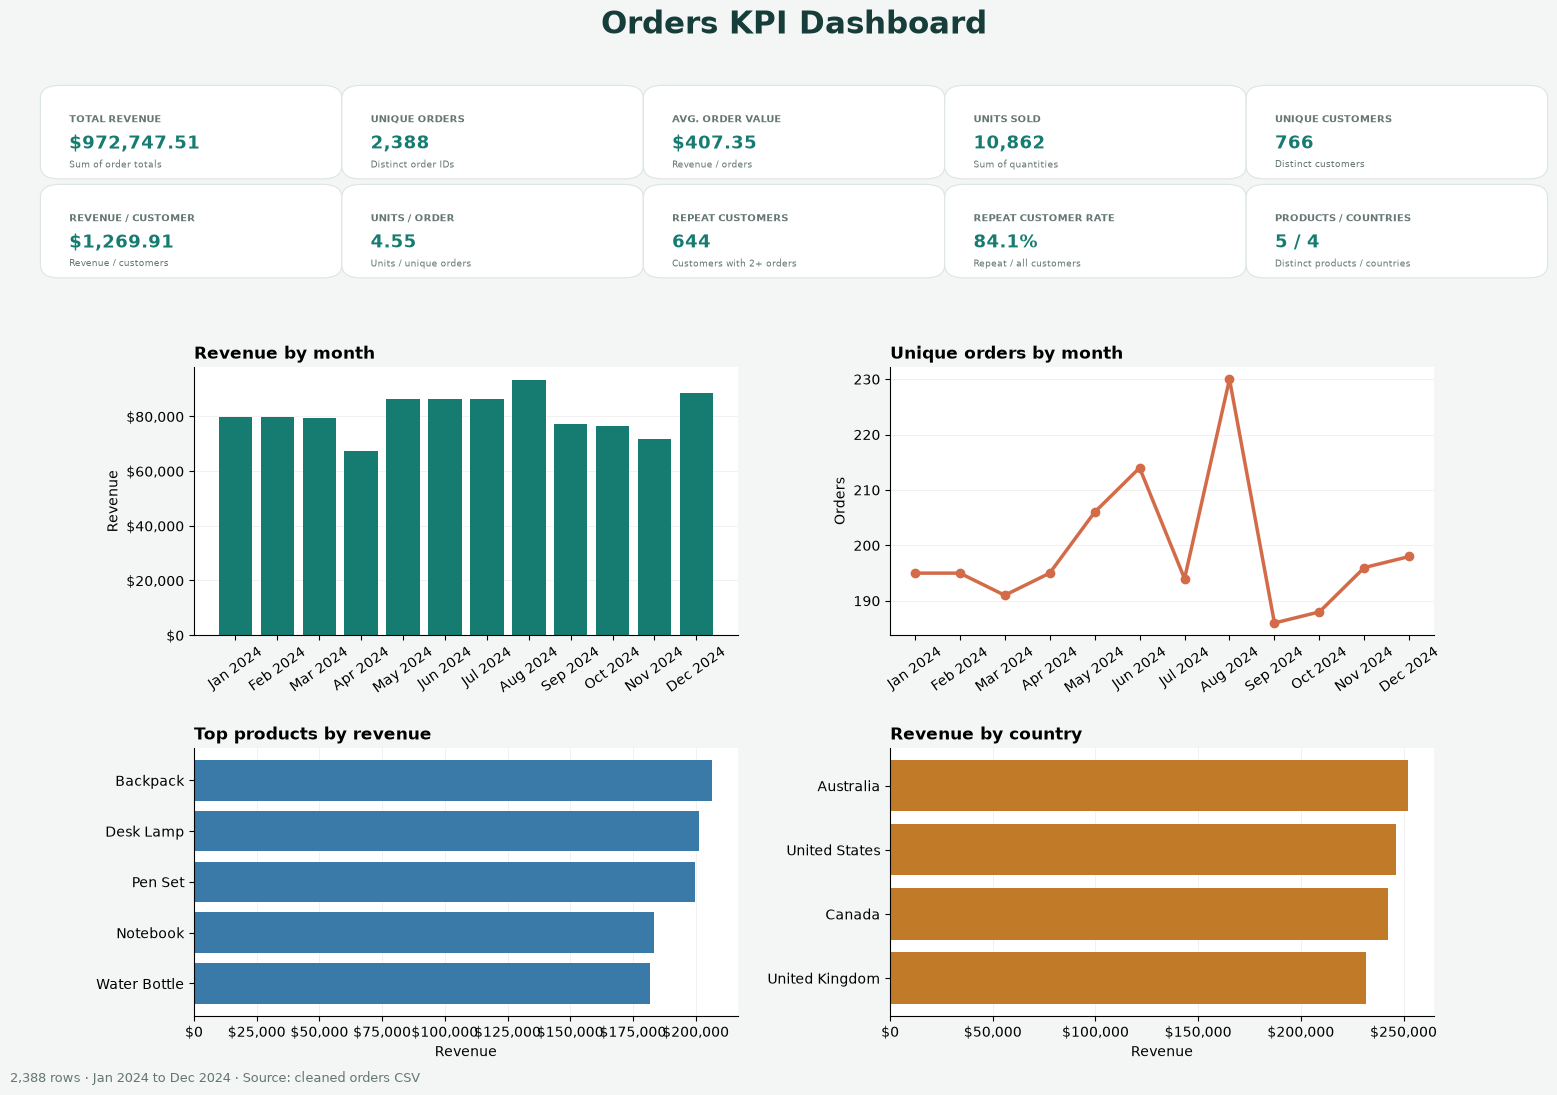

In [16]:
"""Display an orders KPI dashboard using Matplotlib, locally in PyCharm/Jupyter.

Input CSV expected columns:
order_id, customer_id, order_date, product, quantity, country, total

Run from a terminal:
    python3 orders_kpi_dashboard.py

Run from a Jupyter notebook:
    from orders_kpi_dashboard import main
    main([])
"""

import argparse
import csv
import sys
from collections import defaultdict
from datetime import date
from decimal import Decimal, InvalidOperation
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

REQUIRED_COLUMNS = {
    "order_id", "customer_id", "order_date", "product",
    "quantity", "country", "total",
}


def load_orders(input_path):
    """Load and validate the cleaned orders CSV."""
    input_path = Path(input_path).expanduser()
    if not input_path.is_file():
        raise FileNotFoundError(
            f"Input CSV not found: {input_path}\n"
            "Place cleaned_orders.csv in ~/Downloads or pass --input /path/to/file.csv."
        )

    orders = []
    with input_path.open(newline="", encoding="utf-8-sig") as input_file:
        reader = csv.DictReader(input_file)
        if not reader.fieldnames:
            raise ValueError("Input CSV is empty or has no header.")

        reader.fieldnames = [
            (name or "").strip().lstrip("\ufeff").strip().lower()
            for name in reader.fieldnames
        ]
        if len(reader.fieldnames) != len(set(reader.fieldnames)):
            raise ValueError("Input CSV has duplicate column names after normalization.")

        missing = REQUIRED_COLUMNS - set(reader.fieldnames)
        if missing:
            raise ValueError("Input is missing columns: " + ", ".join(sorted(missing)))

        for line_number, row in enumerate(reader, start=2):
            if None in row or any(value is None for value in row.values()):
                raise ValueError(f"Malformed CSV record at line {line_number}.")
            try:
                order_date = date.fromisoformat(row["order_date"].strip())
                order_id = row["order_id"].strip()
                customer_id = row["customer_id"].strip()
                product = row["product"].strip()
                country = row["country"].strip()
                quantity = int(row["quantity"])
                total = Decimal(row["total"].strip())
            except (ValueError, InvalidOperation, AttributeError) as error:
                raise ValueError(f"Invalid data at CSV line {line_number}: {error}") from error

            if not order_id or not customer_id or not product or not country:
                raise ValueError(f"Missing required value at CSV line {line_number}.")
            if quantity <= 0:
                raise ValueError(f"Quantity must be positive at CSV line {line_number}.")
            if not total.is_finite() or total < 0:
                raise ValueError(f"Total must be finite and non-negative at CSV line {line_number}.")

            orders.append({
                "order_id": order_id,
                "customer_id": customer_id,
                "date": order_date,
                "month": order_date.strftime("%Y-%m"),
                "product": product,
                "country": country,
                "quantity": quantity,
                "total": total,
            })

    if not orders:
        raise ValueError("Input dataset contains no orders.")
    return orders


def money(value):
    return f"${value:,.2f}"


def build_dashboard(orders):
    """Create a Matplotlib dashboard figure and return it."""
    revenue = sum((order["total"] for order in orders), Decimal("0"))
    order_count = len({order["order_id"] for order in orders})
    customer_orders = defaultdict(set)
    customer_revenue = defaultdict(lambda: Decimal("0"))
    customer_units = defaultdict(int)
    product_revenue = defaultdict(lambda: Decimal("0"))
    country_revenue = defaultdict(lambda: Decimal("0"))
    monthly_revenue = defaultdict(lambda: Decimal("0"))
    monthly_orders = defaultdict(set)
    units_sold = 0

    for order in orders:
        order_id = order["order_id"]
        customer_id = order["customer_id"]
        amount = order["total"]
        quantity = order["quantity"]

        monthly_revenue[order["month"]] += amount
        monthly_orders[order["month"]].add(order_id)
        product_revenue[order["product"]] += amount
        country_revenue[order["country"]] += amount
        customer_orders[customer_id].add(order_id)
        customer_revenue[customer_id] += amount
        customer_units[customer_id] += quantity
        units_sold += quantity

    order_count = len({order["order_id"] for order in orders})
    customer_count = len(customer_orders)
    avg_order_value = revenue / order_count if order_count else Decimal("0")
    revenue_per_customer = revenue / customer_count if customer_count else Decimal("0")
    units_per_order = Decimal(units_sold) / order_count if order_count else Decimal("0")
    repeat_customers = sum(1 for order_ids in customer_orders.values() if len(order_ids) > 1)
    repeat_customer_rate = (100 * repeat_customers / customer_count) if customer_count else 0.0
    product_count = len(product_revenue)
    country_count = len(country_revenue)

    months = sorted(monthly_revenue)
    month_labels = [date.fromisoformat(f"{month}-01").strftime("%b %Y") for month in months]
    month_values = [float(monthly_revenue[month]) for month in months]
    order_values = [len(monthly_orders[month]) for month in months]

    top_products = sorted(product_revenue.items(), key=lambda item: item[1], reverse=True)[:10]
    top_countries = sorted(country_revenue.items(), key=lambda item: item[1], reverse=True)[:10]

    # Keep charts legible while adding two rows of KPI cards.
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    fig.patch.set_facecolor("#f3f6f4")
    fig.suptitle("Orders KPI Dashboard", y=0.985, fontsize=22,
                 fontweight="bold", color="#173d3a")
    fig.subplots_adjust(top=0.66, bottom=0.07, hspace=0.42, wspace=0.28)

    top_product = max(product_revenue.items(), key=lambda item: item[1], default=("N/A", Decimal("0")))
    top_country = max(country_revenue.items(), key=lambda item: item[1], default=("N/A", Decimal("0")))
    top_product_share = (float(top_product[1] / revenue * 100) if revenue else 0.0)
    top_country_share = (float(top_country[1] / revenue * 100) if revenue else 0.0)

    kpi_text = [
        ("TOTAL REVENUE", money(revenue), "Sum of order totals"),
        ("UNIQUE ORDERS", f"{order_count:,}", "Distinct order IDs"),
        ("AVG. ORDER VALUE", money(avg_order_value), "Revenue / orders"),
        ("UNITS SOLD", f"{units_sold:,}", "Sum of quantities"),
        ("UNIQUE CUSTOMERS", f"{customer_count:,}", "Distinct customers"),
        ("REVENUE / CUSTOMER", money(revenue_per_customer), "Revenue / customers"),
        ("UNITS / ORDER", f"{units_per_order:.2f}", "Units / unique orders"),
        ("REPEAT CUSTOMERS", f"{repeat_customers:,}", "Customers with 2+ orders"),
        ("REPEAT CUSTOMER RATE", f"{repeat_customer_rate:.1f}%", "Repeat / all customers"),
        ("PRODUCTS / COUNTRIES", f"{product_count:,} / {country_count:,}", "Distinct products / countries"),
    ]

    # Draw 10 KPI cards in two rows of five.
    from matplotlib.patches import FancyBboxPatch
    card_left, card_right = 0.035, 0.965
    card_gap = 0.012
    card_width = (card_right - card_left - 4 * card_gap) / 5
    card_height = 0.073
    row_ys = (0.865, 0.775)
    for index, (label, value, description) in enumerate(kpi_text):
        row = index // 5
        col = index % 5
        x = card_left + col * (card_width + card_gap)
        y = row_ys[row]
        card = FancyBboxPatch(
            (x, y - 0.028), card_width, card_height,
            boxstyle="round,pad=0.006,rounding_size=0.012",
            transform=fig.transFigure, facecolor="white",
            edgecolor="#dce6e0", linewidth=0.8, zorder=0,
        )
        fig.add_artist(card)
        fig.text(x + 0.012, y + 0.020, label, ha="left", va="center",
                 fontsize=7.5, color="#647774", fontweight="bold")
        fig.text(x + 0.012, y - 0.002, value, ha="left", va="center",
                 fontsize=13 if len(value) < 15 else 10.5,
                 color="#167c72", fontweight="bold")
        fig.text(x + 0.012, y - 0.021, description, ha="left", va="center",
                 fontsize=6.5, color="#647774")

    ax = axes[0, 0]
    ax.bar(month_labels, month_values, color="#167c72")
    ax.set_title("Revenue by month", loc="left", fontweight="bold")
    ax.set_ylabel("Revenue")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
    ax.tick_params(axis="x", labelrotation=35)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    ax = axes[0, 1]
    ax.plot(month_labels, order_values, color="#d46b48", marker="o", linewidth=2.5)
    ax.set_title("Unique orders by month", loc="left", fontweight="bold")
    ax.set_ylabel("Orders")
    ax.tick_params(axis="x", labelrotation=35)
    ax.grid(axis="y", alpha=0.25)

    ax = axes[1, 0]
    products = list(reversed(top_products))
    ax.barh([item[0] for item in products], [float(item[1]) for item in products], color="#397aa8")
    ax.set_title("Top products by revenue", loc="left", fontweight="bold")
    ax.set_xlabel("Revenue")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    ax = axes[1, 1]
    countries = list(reversed(top_countries))
    ax.barh([item[0] for item in countries], [float(item[1]) for item in countries], color="#c17a28")
    ax.set_title("Revenue by country", loc="left", fontweight="bold")
    ax.set_xlabel("Revenue")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    for axis in axes.flat:
        axis.set_facecolor("white")
        for spine in ("top", "right"):
            axis.spines[spine].set_visible(False)

    start_date = min(order["date"] for order in orders).strftime("%b %Y")
    end_date = max(order["date"] for order in orders).strftime("%b %Y")
    fig.text(0.01, 0.01, f"{len(orders):,} rows · {start_date} to {end_date} · Source: cleaned orders CSV",
             fontsize=9, color="#647774")
    return fig


def main(argv=None):
    downloads = Path.home() / "Downloads"
    script_dir = Path.cwd()
    default_input = downloads / "cleaned_orders.csv"
    if not default_input.is_file():
        candidates = (script_dir / "cleaned_orders.csv", script_dir / "data" / "cleaned_orders.csv")
        default_input = next((path for path in candidates if path.is_file()), default_input)

    parser = argparse.ArgumentParser(
        description="Display an interactive local Matplotlib dashboard for cleaned orders."
    )
    parser.add_argument("--input", default=str(default_input), help="Cleaned orders CSV path.")
    parser.add_argument("--save", default=None, help="Optional path to save a PNG snapshot of the dashboard.")
    args = parser.parse_args(argv)

    orders = load_orders(args.input)
    figure = build_dashboard(orders)
    if args.save:
        save_path = Path(args.save).expanduser()
        save_path.parent.mkdir(parents=True, exist_ok=True)
        figure.savefig(save_path, dpi=160, bbox_inches="tight")
        print(f"Saved dashboard image: {save_path.resolve()}")

    print(f"Loaded {len(orders):,} rows from {Path(args.input).expanduser().resolve()}")
    print("Showing dashboard in the IDE plotting pane/window. Close the figure to finish.")
    plt.show()


if __name__ == "__main__":
    # Jupyter kernels inject their own command-line flags. Ignore them when
    # this file is executed in a notebook; preserve CLI arguments in a terminal.
    main([] if "ipykernel" in sys.modules else None)
